# Lab: from text to BERT

## Setup

In [2]:
# Optional, only if a package is missing in your environment (Kaggle images already include these):
# !pip install -q transformers tokenizers datasets

import collections
import math
import random

import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
import datasets
import tokenizers
import transformers

RUN_TOKENIZER_TRAINING = False  # Vocabulary study is opt-in; no model is trained.
SEED = 42
random.seed(SEED)
torch.manual_seed(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("PyTorch", torch.__version__, "| transformers", transformers.__version__,
      "| tokenizers", tokenizers.__version__, "| datasets", datasets.__version__)
print("device:", device, "(" + torch.cuda.get_device_name(0) + ")" if device.type == "cuda" else "")
if device.type != "cuda":
    print("No GPU found: Parts A and B are fine, Part C will be slow. On Kaggle, enable the GPU accelerator.")


PyTorch 2.11.0+cu130 | transformers 5.20.2 | tokenizers 0.23.3 | datasets 4.8.5
device: cuda (Tesla T4)


# Part A - Subword tokenization

## Exercise 1 - Apply BPE merges (2 marks)


In [3]:
TOY_BASE_VOCAB = set("bghnpsu")
TOY_MERGES = [(("u", "g"), "ug"), (("u", "n"), "un"), (("h", "ug"), "hug")]

In [4]:
def bpe_tokenize_word(word, merges, base_vocab, unk_token="[UNK]"):
    tokens = []
    for char in word:
        tokens.append(char if char in base_vocab else unk_token)
    for (left, right), merged in merges:
        result = []
        i = 0
        while i < len(tokens):
            if i + 1 < len(tokens) and tokens[i] == left and tokens[i + 1] == right:
                result.append(merged)
                i += 2
            else:
                result.append(tokens[i])
                i += 1
        tokens = result
    return tokens


In [5]:
cases = {
    "hugs":  ["hug", "s"],
    "bug":   ["b", "ug"],
    "pun":   ["p", "un"],
    "mug":   ["[UNK]", "ug"],
    "thug":  ["[UNK]", "hug"],
    "unhug": ["un", "hug"],
}
for word, expected in cases.items():
    got = bpe_tokenize_word(word, TOY_MERGES, TOY_BASE_VOCAB)
    assert got == expected, f"{word!r}: expected {expected}, got {got}"
    print(f"{word:6s} -> {got}")
print("Exercise 1 checks passed.")

hugs   -> ['hug', 's']
bug    -> ['b', 'ug']
pun    -> ['p', 'un']
mug    -> ['[UNK]', 'ug']
thug   -> ['[UNK]', 'hug']
unhug  -> ['un', 'hug']
Exercise 1 checks passed.


## Exercise 2 - WordPiece longest match (2 marks)


In [6]:
TOY_WP_VOCAB = {"[UNK]", "b", "h", "p", "u", "##u", "##g", "##n", "##s", "hu", "hug", "##gs", "##un"}

In [7]:
def wordpiece_tokenize_word(word, vocab, unk_token="[UNK]", prefix="##"):
    tokens = []
    start = 0
    while start < len(word):
        end = len(word)
        match = None
        while end > start:
            piece = word[start:end]
            if start > 0:
                piece = prefix + piece
            if piece in vocab:
                match = piece
                break
            end -= 1
        if match is None:
            return [unk_token]
        tokens.append(match)
        start = end
    return tokens


In [8]:
cases = {
    "hugs":  ["hug", "##s"],          # longest match takes "hug", not "hu" + "##gs"
    "bun":   ["b", "##un"],
    "pugs":  ["p", "##u", "##gs"],
    "hu":    ["hu"],
    "mug":   ["[UNK]"],               # no piece starts with "m": the whole word is unknown
    "hugsx": ["[UNK]"],               # "x" fails at the end, and the whole word still becomes [UNK]
}
for word, expected in cases.items():
    got = wordpiece_tokenize_word(word, TOY_WP_VOCAB)
    assert got == expected, f"{word!r}: expected {expected}, got {got}"
    print(f"{word:6s} -> {got}")
print("Exercise 2 checks passed.")

hugs   -> ['hug', '##s']
bun    -> ['b', '##un']
pugs   -> ['p', '##u', '##gs']
hu     -> ['hu']
mug    -> ['[UNK]']
hugsx  -> ['[UNK]']
Exercise 2 checks passed.


## Exercise 3 - How vocabulary size changes sequence length (2 marks)

In [9]:
from datasets import load_dataset

wiki = load_dataset("Salesforce/wikitext", "wikitext-2-raw-v1")

def clean(lines):
    """Drop empty lines and '= Heading =' lines."""
    return [s.strip() for s in lines if s.strip() and not s.strip().startswith("=")]

train_texts, val_texts = clean(wiki["train"]["text"]), clean(wiki["validation"]["text"])
print(f"train paragraphs: {len(train_texts):,} | validation paragraphs: {len(val_texts):,}")
print("example:", val_texts[0][:200], "...")

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

wikitext-2-raw-v1/test-00000-of-00001.pa(…): reconstructing file:   0%|          |  0.00B /  733kB            

wikitext-2-raw-v1/test-00000-of-00001.pa(…): downloading bytes:           |  0.00B            

wikitext-2-raw-v1/train-00000-of-00001.p(…): reconstructing file:   0%|          |  0.00B / 6.36MB            

wikitext-2-raw-v1/train-00000-of-00001.p(…): downloading bytes:           |  0.00B            

...

wikitext-2-raw-v1/validation-00000-of-00(…): downloading bytes:           |  0.00B            

Generating test split:   0%|          | 0/4358 [00:00<?, ? examples/s]

Generating train split:   0%|          | 0/36718 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/3760 [00:00<?, ? examples/s]

train paragraphs: 17,556 | validation paragraphs: 1,841
example: Homarus gammarus , known as the European lobster or common lobster , is a species of clawed lobster from the eastern Atlantic Ocean , Mediterranean Sea and parts of the Black Sea . It is closely relat ...


In [10]:
from tokenizers import Tokenizer, models, normalizers, pre_tokenizers, trainers

def train_subword_tokenizer(kind, texts, vocab_size):
    """Train a lowercasing BPE or WordPiece tokenizer on `texts` (training split only)."""
    if kind == "bpe":
        tok = Tokenizer(models.BPE(unk_token="[UNK]"))
        trainer = trainers.BpeTrainer(vocab_size=vocab_size, special_tokens=["[UNK]"])
    elif kind == "wordpiece":
        tok = Tokenizer(models.WordPiece(unk_token="[UNK]"))
        trainer = trainers.WordPieceTrainer(vocab_size=vocab_size, special_tokens=["[UNK]"])
    else:
        raise ValueError(kind)
    tok.normalizer = normalizers.Lowercase()
    tok.pre_tokenizer = pre_tokenizers.Whitespace()      # words = runs of letters/digits, or of punctuation
    tok.train_from_iterator(texts, trainer=trainer)
    return tok

if RUN_TOKENIZER_TRAINING:
    demo = train_subword_tokenizer("wordpiece", train_texts, vocab_size=4000)
    enc = demo.encode("Tokenization is unbelievably useful.")
    print("tokens  :", enc.tokens)
    print("word_ids:", enc.word_ids, " <- index of the pre-tokenized word each token came from")


In [11]:
def subword_stats(tokenizer, texts):
    n_words = n_tokens = n_split = n_unk = 0
    all_tokens = 0
    for enc in tokenizer.encode_batch(texts):
        counts = collections.Counter()
        for word_id in enc.word_ids:
            if word_id is not None:
                counts[word_id] += 1
        n_words += len(counts)
        n_tokens += sum(counts.values())
        for count in counts.values():
            if count > 1:
                n_split += 1
        n_unk += enc.tokens.count("[UNK]")
        all_tokens += len(enc.tokens)
    return {
        "fertility": n_tokens / n_words if n_words else 0.0,
        "split_rate": n_split / n_words if n_words else 0.0,
        "unk_rate": n_unk / all_tokens if all_tokens else 0.0,
    }


In [12]:
if RUN_TOKENIZER_TRAINING:
    toy = subword_stats(demo, ["tokenization is useful"])
    assert set(toy) == {"fertility", "split_rate", "unk_rate"}
    assert toy["fertility"] >= 1.0 and 0.0 <= toy["split_rate"] <= 1.0
    manual = demo.encode("tokenization is useful")
    assert abs(toy["fertility"] - len(manual.tokens) / 3) < 1e-9, "fertility should be tokens / words (3 words here)"
    print("Exercise 3 checks passed. Now running the vocabulary-size study (a minute or so)...")

    VOCAB_SIZES = [1000, 4000, 16000]
    study = {}
    for kind in ("bpe", "wordpiece"):
        for size in VOCAB_SIZES:
            tok = train_subword_tokenizer(kind, train_texts, size)              # trained on train only
            study[(kind, size)] = (tok, subword_stats(tok, val_texts))          # measured on validation
            s = study[(kind, size)][1]
            print(f"{kind:9s} V={size:6,d}  fertility={s['fertility']:.3f}  split_rate={s['split_rate']:.3f}  unk_rate={s['unk_rate']:.4f}")

    fig, ax = plt.subplots(figsize=(5.5, 3.4))
    for kind, marker in (("bpe", "o"), ("wordpiece", "s")):
        ax.plot(VOCAB_SIZES, [study[(kind, v)][1]["fertility"] for v in VOCAB_SIZES], marker=marker, label=kind)
    ax.set_xscale("log"); ax.set_xticks(VOCAB_SIZES); ax.set_xticklabels([f"{v:,}" for v in VOCAB_SIZES])
    ax.set_xlabel("vocabulary size (log scale)"); ax.set_ylabel("tokens per word (validation)")
    ax.set_title("Larger vocabularies give shorter sequences"); ax.legend(); plt.tight_layout(); plt.show()

    for word in ["photosynthesis", "unbelievably", "bennett", "transformers", "kaggle"]:
        print(f"{word:15s}", " | ".join(f"{k[0]} {v:>5}: {study[(k, v)][0].encode(word).tokens}"
                                        for k in ("bpe", "wordpiece") for v in (1000, 16000)))


## Exercise 4 - One sentence, three pretrained tokenizers, three languages (2 marks)

In [13]:
from transformers import AutoTokenizer

PRETRAINED = ["google-bert/bert-base-uncased", "google-bert/bert-base-multilingual-cased", "openai-community/gpt2"]
pretrained_toks = {name: AutoTokenizer.from_pretrained(name) for name in PRETRAINED}   # tokenizers only: small downloads

SENTENCES = {
    "English":  "I like Indian food very much.",
    "Hindi":    "मुझे भारतीय खाना बहुत पसंद है।",
    "Hinglish": "Mujhe Indian khana bahut pasand hai.",
}

config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

config.json:   0%|          | 0.00/625 [00:00<?, ?B/s]

...

config.json:   0%|          | 0.00/665 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/26.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/1.04M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

In [14]:
def tokens_per_word(tokenizer, text):
    words = text.split()
    if not words:
        return 0.0
    return len(tokenizer.tokenize(text)) / len(words)


In [15]:
assert abs(tokens_per_word(pretrained_toks[PRETRAINED[0]], "hello world") - len(pretrained_toks[PRETRAINED[0]].tokenize("hello world")) / 2) < 1e-9
print("Exercise 4 checks passed.\n")

print(f"{'':10s}" + "".join(f"{name.split('/')[-1]:>30s}" for name in PRETRAINED))
for lang, text in SENTENCES.items():
    print(f"{lang:10s}" + "".join(f"{tokens_per_word(pretrained_toks[n], text):30.2f}" for n in PRETRAINED))

for lang, text in SENTENCES.items():
    print(f"\n{lang}: {text}")
    for name in PRETRAINED:
        tok = pretrained_toks[name]
        pieces = tok.tokenize(text)
        print(f"  {name.split('/')[-1]:28s} {len(pieces):2d} tokens: {pieces}")
        if "uncased" in name:
            print(f"  {'':28s} decoded back: {tok.decode(tok.encode(text, add_special_tokens=False))!r}")

Exercise 4 checks passed.

                       bert-base-uncased  bert-base-multilingual-cased                          gpt2
English                             1.17                          1.17                          1.17
Hindi                               3.17                          2.17                          7.83
Hinglish                            2.17                          2.00                          2.33

English: I like Indian food very much.
  bert-base-uncased             7 tokens: ['i', 'like', 'indian', 'food', 'very', 'much', '.']
                               decoded back: 'i like indian food very much.'
  bert-base-multilingual-cased  7 tokens: ['I', 'like', 'Indian', 'food', 'very', 'much', '.']
  gpt2                          7 tokens: ['I', 'Ġlike', 'ĠIndian', 'Ġfood', 'Ġvery', 'Ġmuch', '.']

Hindi: मुझे भारतीय खाना बहुत पसंद है।
  bert-base-uncased            19 tokens: ['[UNK]', 'भ', '##ा', '##र', '##त', '##ी', '##य', 'ख', '##ा', '##न', '##ा', 'ब', 

# Part B - Self-attention with a padding mask

## Exercise 5 - Scaled dot-product attention with a mask (3 marks)

In [16]:
def scaled_dot_product_attention(q, k, v, mask=None):
    scores = torch.matmul(q, k.transpose(-2, -1)) / math.sqrt(q.size(-1))
    if mask is not None:
        scores = scores.masked_fill(~mask, float("-inf"))
    weights = torch.softmax(scores, dim=-1)
    output = torch.matmul(weights, v)
    return output, weights


In [17]:
g = torch.Generator().manual_seed(0)
B, H, T, d_k = 2, 3, 5, 4
q, k, v = (torch.randn(B, H, T, d_k, generator=g) for _ in range(3))
lengths = torch.tensor([5, 3])                                            # sequence 2 has 2 padded positions
key_mask = (torch.arange(T)[None, :] < lengths[:, None])[:, None, None, :]   # (B, 1, 1, T), True = real token

out, w = scaled_dot_product_attention(q, k, v, key_mask)
assert out.shape == (B, H, T, d_k) and w.shape == (B, H, T, T), "wrong output shapes"
assert torch.allclose(w.sum(-1), torch.ones(B, H, T)), "each row of weights must sum to 1"
assert (w[1, :, :, 3:] == 0).all(), "padded keys must receive exactly zero weight"
ref = F.scaled_dot_product_attention(q, k, v, attn_mask=key_mask)
assert torch.allclose(out, ref, atol=1e-5), "does not match torch's scaled_dot_product_attention"
out_nomask, _ = scaled_dot_product_attention(q, k, v)
assert torch.allclose(out_nomask, F.scaled_dot_product_attention(q, k, v), atol=1e-5), "mask=None case is wrong"
print("Exercise 5 checks passed.")

Exercise 5 checks passed.


## Exercise 6  The padding mask (1 mark)

In [18]:
def make_padding_mask(input_ids, pad_id):
    return (input_ids != pad_id)[:, None, None, :]


In [19]:
ids = torch.tensor([[5, 6, 7, 0, 0], [8, 9, 10, 11, 12]])
m = make_padding_mask(ids, pad_id=0)
assert m.shape == (2, 1, 1, 5) and m.dtype == torch.bool
assert m[0, 0, 0].tolist() == [True, True, True, False, False] and m[1].all()
print("Exercise 6 checks passed.")

Exercise 6 checks passed.


## Provided: a small Transformer encoder


In [20]:
class MultiHeadSelfAttention(nn.Module):
    def __init__(self, d_model, n_heads):
        super().__init__()
        assert d_model % n_heads == 0
        self.h, self.d_k = n_heads, d_model // n_heads
        self.W_q, self.W_k, self.W_v, self.W_o = (nn.Linear(d_model, d_model) for _ in range(4))

    def forward(self, x, mask=None):                                   # x: (B, T, D)
        B, T, D = x.shape
        split = lambda t: t.view(B, T, self.h, self.d_k).transpose(1, 2)        # (B, H, T, d_k)
        out, weights = scaled_dot_product_attention(split(self.W_q(x)), split(self.W_k(x)), split(self.W_v(x)), mask)
        return self.W_o(out.transpose(1, 2).reshape(B, T, D)), weights          # merge heads -> (B, T, D)


class EncoderLayer(nn.Module):
    def __init__(self, d_model, n_heads, d_ff, dropout=0.1):
        super().__init__()
        self.attn = MultiHeadSelfAttention(d_model, n_heads)
        self.ff = nn.Sequential(nn.Linear(d_model, d_ff), nn.ReLU(), nn.Linear(d_ff, d_model))
        self.norm1, self.norm2 = nn.LayerNorm(d_model), nn.LayerNorm(d_model)
        self.drop = nn.Dropout(dropout)

    def forward(self, x, mask=None):
        a, _ = self.attn(x, mask)
        x = self.norm1(x + self.drop(a))                  # residual + layer norm (post-norm, as in the paper)
        return self.norm2(x + self.drop(self.ff(x)))


class TinyEncoder(nn.Module):
    def __init__(self, vocab_size, d_model=32, n_heads=4, d_ff=64, n_layers=2, max_len=64, pad_id=0):
        super().__init__()
        self.emb = nn.Embedding(vocab_size, d_model, padding_idx=pad_id)
        pos = torch.arange(max_len)[:, None]
        div = torch.exp(torch.arange(0, d_model, 2) * (-math.log(10000.0) / d_model))
        pe = torch.zeros(max_len, d_model)
        pe[:, 0::2], pe[:, 1::2] = torch.sin(pos * div), torch.cos(pos * div)
        self.register_buffer("pe", pe)
        self.layers = nn.ModuleList(EncoderLayer(d_model, n_heads, d_ff) for _ in range(n_layers))

    def forward(self, ids, mask=None):                   # ids: (B, T)
        x = self.emb(ids) * math.sqrt(self.emb.embedding_dim) + self.pe[: ids.size(1)]
        for layer in self.layers:
            x = layer(x, mask)
        return x                                          # (B, T, D)

torch.manual_seed(SEED)
encoder = TinyEncoder(vocab_size=50).eval()               # eval(): dropout off, so outputs are deterministic
print(encoder(torch.tensor([[3, 4, 5, 0]]), make_padding_mask(torch.tensor([[3, 4, 5, 0]]), 0)).shape)

torch.Size([1, 4, 32])


## Exercise 7 - Prove that padding cannot leak (2 marks)


In [21]:
@torch.no_grad()
def padding_leakage(model, ids, junk_ids, pad_id, use_mask=True):
    model.eval()
    mask = make_padding_mask(ids, pad_id) if use_mask else None
    first = model(ids, mask)
    second = model(junk_ids, mask)
    difference = (first - second).abs()[ids != pad_id]
    return difference.max().item() if difference.numel() else 0.0


In [22]:
ids = torch.tensor([[7, 8, 9, 0, 0, 0], [10, 11, 12, 13, 14, 0]])
junk_ids = ids.clone()
junk_ids[ids == 0] = torch.tensor([31, 32, 33, 34])       # change only the padded positions
with_mask = padding_leakage(encoder, ids, junk_ids, pad_id=0, use_mask=True)
without_mask = padding_leakage(encoder, ids, junk_ids, pad_id=0, use_mask=False)
print(f"with mask   : max change at real positions = {with_mask:.2e}")
print(f"without mask: max change at real positions = {without_mask:.2e}")
assert with_mask < 1e-5, "with the mask, real positions must not depend on padded content"
assert without_mask > 1e-3, "without the mask, padded content should leak into real positions"
print("Exercise 7 checks passed.")

with mask   : max change at real positions = 0.00e+00
without mask: max change at real positions = 7.28e-01
Exercise 7 checks passed.


# Part C - BERT: inputs, objective, and predictions


In [23]:
from transformers import AutoModelForMaskedLM

BERT = "google-bert/bert-base-uncased"
bert_tok = AutoTokenizer.from_pretrained(BERT)
bert_mlm = AutoModelForMaskedLM.from_pretrained(BERT).to(device).eval()     # eval(): dropout off
print("vocabulary size:", bert_tok.vocab_size, "| parameters:", round(sum(p.numel() for p in bert_mlm.parameters()) / 1e6, 1), "M")
print("special tokens:", {t: bert_tok.convert_tokens_to_ids(t) for t in ["[PAD]", "[UNK]", "[CLS]", "[SEP]", "[MASK]"]})

model.safetensors: reconstructing file:   0%|          |  0.00B /  440MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/202 [00:00<?, ?it/s]

[transformers] BertForMaskedLM LOAD REPORT from: google-bert/bert-base-uncased
Key                         | Status     |  | 
----------------------------+------------+--+-
cls.seq_relationship.bias   | UNEXPECTED |  | 
bert.pooler.dense.bias      | UNEXPECTED |  | 
bert.pooler.dense.weight    | UNEXPECTED |  | 
cls.seq_relationship.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


vocabulary size: 30522 | parameters: 109.5 M
special tokens: {'[PAD]': 0, '[UNK]': 100, '[CLS]': 101, '[SEP]': 102, '[MASK]': 103}


## Exercise 8 - BERT's three input tensors (2 marks)

In [24]:
pair = bert_tok("The cat sat on the mat.", "It looked very comfortable.",
                padding="max_length", max_length=20, return_tensors="pt")
print(f"{'pos':>3}  {'token':12s} {'input_id':>8} {'type':>4} {'attn':>4}")
for i, (tid, tt, am) in enumerate(zip(pair["input_ids"][0], pair["token_type_ids"][0], pair["attention_mask"][0])):
    print(f"{i:3d}  {bert_tok.convert_ids_to_tokens(int(tid)):12s} {int(tid):8d} {int(tt):4d} {int(am):4d}")

pos  token        input_id type attn
  0  [CLS]             101    0    1
  1  the              1996    0    1
  2  cat              4937    0    1
  3  sat              2938    0    1
  4  on               2006    0    1
  5  the              1996    0    1
  6  mat             13523    0    1
  7  .                1012    0    1
  8  [SEP]             102    0    1
  9  it               2009    1    1
 10  looked           2246    1    1
 11  very             2200    1    1
 12  comfortable      6625    1    1
 13  .                1012    1    1
 14  [SEP]             102    1    1
 15  [PAD]               0    0    0
 16  [PAD]               0    0    0
 17  [PAD]               0    0    0
 18  [PAD]               0    0    0
 19  [PAD]               0    0    0


In [25]:
def describe_bert_input(enc, tokenizer):
    ids = enc["input_ids"][0]
    types = enc["token_type_ids"][0]
    real = enc["attention_mask"][0].bool()
    cls_position = (ids == tokenizer.cls_token_id).nonzero()[0].item()
    sep_positions = (ids == tokenizer.sep_token_id).nonzero().flatten().tolist()
    return {
        "cls_position": cls_position,
        "sep_positions": sep_positions,
        "segment_b_tokens": ((types == 1) & real).sum().item(),
        "pad_tokens": (~real).sum().item(),
    }


In [26]:
info = describe_bert_input(pair, bert_tok)
print(info)
tokens_b = bert_tok.tokenize("It looked very comfortable.")
assert info["cls_position"] == 0
assert len(info["sep_positions"]) == 2
assert info["segment_b_tokens"] == len(tokens_b) + 1, "segment B = sentence-B tokens plus its closing [SEP]"
assert info["pad_tokens"] == 20 - (info["sep_positions"][-1] + 1)
print("Exercise 8 checks passed.")

{'cls_position': 0, 'sep_positions': [8, 14], 'segment_b_tokens': 6, 'pad_tokens': 5}
Exercise 8 checks passed.


## Exercise 9 - BERT's 80/10/10 masking rule (4 marks)

In [27]:
# A batch of real text: 512 validation paragraphs, truncated to 128 tokens.
mlm_batch = bert_tok(val_texts[:512], padding=True, truncation=True, max_length=128,
                     return_tensors="pt", return_special_tokens_mask=True)
special_mask = mlm_batch["special_tokens_mask"].bool() | (mlm_batch["attention_mask"] == 0)   # never select these
print("batch shape:", tuple(mlm_batch["input_ids"].shape), "| eligible tokens:", int((~special_mask).sum()))

batch shape: (512, 128) | eligible tokens: 44242


In [28]:
def mask_tokens(input_ids, special_mask, mask_token_id, vocab_size, mlm_prob=0.15, generator=None):
    labels = input_ids.clone()
    masked_ids = input_ids.clone()
    shape = input_ids.shape
    selected = torch.rand(shape, generator=generator, device=input_ids.device) < mlm_prob
    selected = selected & ~special_mask.bool()
    labels[~selected] = -100

    # One draw chooses 80% mask, 10% random, and 10% unchanged.
    choice = torch.rand(shape, generator=generator, device=input_ids.device)
    replace_mask = selected & (choice < 0.8)
    replace_random = selected & (choice >= 0.8) & (choice < 0.9)
    masked_ids[replace_mask] = mask_token_id
    random_ids = torch.randint(vocab_size, shape, generator=generator, device=input_ids.device)
    masked_ids[replace_random] = random_ids[replace_random]
    return masked_ids, labels


In [29]:
original = mlm_batch["input_ids"].clone()
masked_ids, labels = mask_tokens(mlm_batch["input_ids"], special_mask, bert_tok.mask_token_id, bert_tok.vocab_size,
                                 mlm_prob=0.15, generator=torch.Generator().manual_seed(SEED))

assert torch.equal(mlm_batch["input_ids"], original), "input_ids was modified in place"
selected = labels != -100
assert not (selected & special_mask).any(), "special tokens or padding were selected"
assert torch.equal(labels[selected], original[selected]), "labels must hold the ORIGINAL token at selected positions"
assert torch.equal(masked_ids[~selected], original[~selected]), "non-selected positions must be unchanged"

eligible = int((~special_mask).sum()); n_sel = int(selected.sum())
is_mask = (masked_ids == bert_tok.mask_token_id) & selected
is_unchanged = (masked_ids == original) & selected
is_random = selected & ~is_mask & ~is_unchanged
frac = lambda m: int(m.sum()) / n_sel
print(f"selected: {n_sel / eligible:.3f} of eligible tokens (target 0.15)")
print(f"of selected -> [MASK]: {frac(is_mask):.3f} (0.8) | random: {frac(is_random):.3f} (~0.1) | unchanged: {frac(is_unchanged):.3f} (~0.1)")
assert abs(n_sel / eligible - 0.15) < 0.01
assert abs(frac(is_mask) - 0.8) < 0.03 and abs(frac(is_random) - 0.1) < 0.03 and abs(frac(is_unchanged) - 0.1) < 0.03
print("Exercise 9 checks passed.")

selected: 0.148 of eligible tokens (target 0.15)
of selected -> [MASK]: 0.792 (0.8) | random: 0.106 (~0.1) | unchanged: 0.102 (~0.1)
Exercise 9 checks passed.


## Exercise 10 - BERT's top-k predictions (3 marks)


In [30]:
@torch.no_grad()
def top_k_predictions(text, k=5):
    enc = bert_tok(text, return_tensors="pt").to(device)
    positions = (enc["input_ids"][0] == bert_tok.mask_token_id).nonzero().flatten()
    if len(positions) != 1:
        raise ValueError("text must contain exactly one [MASK]")
    logits = bert_mlm(**enc).logits[0, positions.item()]
    probabilities = torch.softmax(logits, dim=-1)
    values, ids = probabilities.topk(k)
    result = []
    for token_id, probability in zip(ids.tolist(), values.tolist()):
        result.append((bert_tok.convert_ids_to_tokens(token_id), probability))
    return result


In [31]:
from transformers import pipeline

preds = top_k_predictions("The cat sat on the [MASK].", k=5)
print(preds)
probs_ = [p for _, p in preds]
assert len(preds) == 5 and probs_ == sorted(probs_, reverse=True) and 0 < sum(probs_) <= 1 + 1e-6
fill = pipeline("fill-mask", model=bert_mlm, tokenizer=bert_tok, device=0 if device.type == "cuda" else -1)
ref = fill("The cat sat on the [MASK].", top_k=1)[0]
assert bert_tok.convert_tokens_to_ids(preds[0][0]) == ref["token"], "top-1 token differs from the fill-mask pipeline"
assert abs(preds[0][1] - ref["score"]) < 1e-3, "top-1 probability differs from the fill-mask pipeline"
print("Exercise 10 checks passed.\n")

for text in ["Paris is the capital of [MASK].",
             "She opened the [MASK] and walked into the room.",
             "The doctor gave me some [MASK] for my headache.",
             "Bennett University is located in [MASK]."]:
    print(f"{text:50s}", [(t, round(p, 3)) for t, p in top_k_predictions(text)])

[('floor', 0.31445708870887756), ('bed', 0.11902346462011337), ('couch', 0.10695997625589371), ('sofa', 0.06032614782452583), ('ground', 0.05508217215538025)]
Exercise 10 checks passed.

Paris is the capital of [MASK].                    [('france', 0.951), ('algeria', 0.012), ('morocco', 0.003), ('reunion', 0.003), ('haiti', 0.003)]
She opened the [MASK] and walked into the room.    [('door', 0.987), ('doors', 0.003), ('window', 0.001), ('curtain', 0.001), ('curtains', 0.001)]
The doctor gave me some [MASK] for my headache.    [('medication', 0.274), ('medicine', 0.088), ('treatment', 0.079), ('help', 0.075), ('water', 0.072)]
Bennett University is located in [MASK].           [('bennett', 0.185), ('omaha', 0.035), ('sacramento', 0.031), ('burlington', 0.026), ('nashville', 0.023)]


### Provided: how often does BERT recover masked tokens?

Your `mask_tokens` output from Exercise 9 is a realistic MLM test set. The cell below runs BERT on it and measures, **separately** for the three kinds of selected positions, how often BERT's most probable token is the original. It also reports the MLM loss that pretraining minimizes (cross-entropy over selected positions only; `labels = -100` elsewhere). This is evaluation only: no weights change. Note that WikiText comes from Wikipedia, which was also part of BERT's pretraining data, so these numbers are likely optimistic.

In [32]:
@torch.no_grad()
def mlm_eval(masked_ids, labels, attention_mask, batch_size=64):
    correct = {"[MASK]": 0, "random": 0, "unchanged": 0}; total = dict.fromkeys(correct, 0); losses = []
    for s in range(0, masked_ids.size(0), batch_size):
        ids_b, lab_b, att_b = (t[s:s + batch_size].to(device) for t in (masked_ids, labels, attention_mask))
        out = bert_mlm(input_ids=ids_b, attention_mask=att_b, labels=lab_b)    # HF computes CE, ignoring -100
        losses.append(out.loss.item())
        pred = out.logits.argmax(-1)
        sel = lab_b != -100
        kinds = {"[MASK]": sel & (ids_b == bert_tok.mask_token_id),
                 "unchanged": sel & (ids_b == lab_b)}
        kinds["random"] = sel & ~kinds["[MASK]"] & ~kinds["unchanged"]
        for name, m in kinds.items():
            correct[name] += int((pred[m] == lab_b[m]).sum()); total[name] += int(m.sum())
    for name in correct:
        print(f"{name:10s} positions: {total[name]:6d}   top-1 accuracy = {correct[name] / max(total[name], 1):.3f}")
    print(f"mean MLM loss over batches = {sum(losses) / len(losses):.3f} nats/token")

mlm_eval(masked_ids, labels, mlm_batch["attention_mask"])

[MASK]     positions:   5196   top-1 accuracy = 0.608
random     positions:    695   top-1 accuracy = 0.499
unchanged  positions:    672   top-1 accuracy = 0.964
mean MLM loss over batches = 2.161 nats/token


## Exercise 11 - A careful bias probe (2 marks)

In [33]:
@torch.no_grad()
def pronoun_probs(sentence):
    enc = bert_tok(sentence, return_tensors="pt").to(device)
    positions = (enc["input_ids"][0] == bert_tok.mask_token_id).nonzero().flatten()
    if len(positions) != 1:
        raise ValueError("sentence must contain exactly one [MASK]")
    logits = bert_mlm(**enc).logits[0, positions.item()]
    probabilities = torch.softmax(logits, dim=-1)
    he_id = bert_tok.convert_tokens_to_ids("he")
    she_id = bert_tok.convert_tokens_to_ids("she")
    return probabilities[he_id].item(), probabilities[she_id].item()


Exercise 11 checks passed.

the {occ} said that [MASK] was tired.
  nurse         P(he)=0.187  P(she)=0.637  log(P(he)/P(she))=-1.22
  receptionist  P(he)=0.075  P(she)=0.815  log(P(he)/P(she))=-2.39
  teacher       P(he)=0.467  P(she)=0.377  log(P(he)/P(she))=+0.21
  doctor        P(he)=0.480  P(she)=0.328  log(P(he)/P(she))=+0.38
  engineer      P(he)=0.820  P(she)=0.053  log(P(he)/P(she))=+2.75
  pilot         P(he)=0.855  P(she)=0.081  log(P(he)/P(she))=+2.36
  programmer    P(he)=0.788  P(she)=0.111  log(P(he)/P(she))=+1.96
  scientist     P(he)=0.691  P(she)=0.142  log(P(he)/P(she))=+1.58
after the meeting, the {occ} explained why [MASK] had to leave early.
  nurse         P(he)=0.085  P(she)=0.355  log(P(he)/P(she))=-1.42
  receptionist  P(he)=0.102  P(she)=0.430  log(P(he)/P(she))=-1.44
  teacher       P(he)=0.327  P(she)=0.273  log(P(he)/P(she))=+0.18
  doctor        P(he)=0.534  P(she)=0.081  log(P(he)/P(she))=+1.89
  engineer      P(he)=0.527  P(she)=0.026  log(P(he)/P(she))

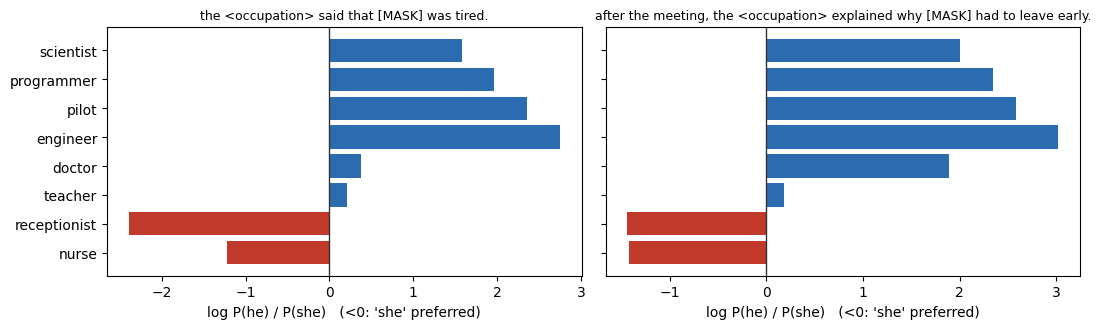

In [34]:
p_he, p_she = pronoun_probs("Yesterday [MASK] went to the market.")
assert 0 <= p_he <= 1 and 0 <= p_she <= 1 and p_he + p_she <= 1 + 1e-6
print("Exercise 11 checks passed.\n")

OCCUPATIONS = ["nurse", "receptionist", "teacher", "doctor", "engineer", "pilot", "programmer", "scientist"]
TEMPLATES = ["the {occ} said that [MASK] was tired.",
             "after the meeting, the {occ} explained why [MASK] had to leave early."]
fig, axes = plt.subplots(1, len(TEMPLATES), figsize=(11, 3.4), sharey=True)
for ax, template in zip(axes, TEMPLATES):
    log_ratios = []
    print(template)
    for occ in OCCUPATIONS:
        he, she = pronoun_probs(template.format(occ=occ))
        log_ratios.append(math.log(he / she))
        print(f"  {occ:13s} P(he)={he:.3f}  P(she)={she:.3f}  log(P(he)/P(she))={log_ratios[-1]:+.2f}")
    ax.barh(OCCUPATIONS, log_ratios, color=["#c0392b" if r < 0 else "#2b6cb0" for r in log_ratios])
    ax.axvline(0, color="#333333", lw=1); ax.set_xlabel("log P(he) / P(she)   (<0: 'she' preferred)")
    ax.set_title(template.replace("{occ}", "<occupation>"), fontsize=9)
plt.tight_layout(); plt.show()